# Bank Campaign Response Prediction

## Part 1 · Define the pre-call decision

Imagine a campaign team has time for 20 calls. Before dialling, which contacts are most likely to subscribe to a term deposit? Each historical record pairs campaign information with a yes/no response. Our aim is to estimate that response from information the team could have at that moment.

### Load the date-ordered records

UCI distributes several versions of the dataset. We use the full additional file and keep the original row order for a later time-based evaluation. The outer ZIP contains a second ZIP, and the CSV uses semicolons between fields. See the [README](README.md) for download instructions.

In [1]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import pandas as pd

archive = Path("data/bank-marketing.zip")
with ZipFile(archive) as outer:
    with ZipFile(BytesIO(outer.read("bank-additional.zip"))) as inner:
        with inner.open("bank-additional/bank-additional-full.csv") as csv_file:
            campaigns = pd.read_csv(csv_file, sep=";")

print(f"{len(campaigns):,} records | {campaigns.shape[1]} columns")

41,188 records | 21 columns


### Decide what the model may see

| Field | Meaning | Use |
|---|---|---|
| job | Job category recorded for the client | Starting input |
| previous | Number of contacts before the current campaign | Starting input |
| poutcome | Outcome of the previous campaign | Starting input |
| duration | Length of the current call in seconds | Exclude because it is unknown before dialling |
| y | Whether the client subscribed | Answer used for learning and evaluation |

In [2]:
target = "y"
pre_call_features = ["job", "previous", "poutcome"]
assert campaigns.shape == (41188, 21), "Check the dataset variant."
assert campaigns[target].notna().all()
assert set(campaigns[target].unique()) == {"yes", "no"}
assert {target, "duration"}.isdisjoint(pre_call_features)

print("Target labels:", sorted(campaigns[target].unique()))
print(campaigns[pre_call_features].head(3).to_string(index=False))

Target labels: ['no', 'yes']
      job  previous    poutcome
housemaid         0 nonexistent
 services         0 nonexistent
 services         0 nonexistent


In the first row, `previous = 0` and `poutcome = nonexistent` describe a client with no previous campaign contact recorded. A previous failure and no previous campaign are different situations. We will preserve that distinction when preparing the data.

### Why the timing matters

A ten-minute conversation may tell us something about interest, but its length is impossible to enter one second before dialling. Including it could make an offline score look better than the real tool could deliver. We start with an explicit list of permitted inputs so that adding a column later requires a reason.

**Next milestone:** Reserve later records before inspecting response rates or choosing features using outcomes. The app will estimate response among contacted customers; this dataset alone cannot establish how many subscriptions were caused by a call.

## Part 2 · Explore campaign responses

**Question.** How common is a subscription in the earlier campaign records, and what can previous campaign outcomes tell us before a new call? We answer these questions on the training period and reserve later observations for model selection and final evaluation.

### 2.1 · Reserve later records before exploration

UCI supplies this file in date order. We keep that order and split by row position: roughly 70% for training, the next 15% for validation, and the final 15% for testing. Training data guides exploration and fitting. Validation will guide model and cutoff choices. The test set is reserved for a final performance estimate. The cut points approximate time periods because the CSV does not provide a complete timestamp or a customer identifier for checking overlap.

In [3]:
n_records = len(campaigns)
train_end = n_records * 70 // 100
validation_end = n_records * 85 // 100

train = campaigns.iloc[:train_end].copy()
validation = campaigns.iloc[train_end:validation_end].copy()
test = campaigns.iloc[validation_end:].copy()

assert train.index.max() < validation.index.min() <= validation.index.max() < test.index.min()
assert len(train) + len(validation) + len(test) == n_records
for name, records in [("Training", train), ("Validation", validation), ("Test", test)]:
    print(f"{name:10} {len(records):>6,} records | source rows {records.index.min()+1:,}–{records.index.max()+1:,}")

Training   28,831 records | source rows 1–28,831
Validation  6,178 records | source rows 28,832–35,009
Test        6,179 records | source rows 35,010–41,188


### 2.2 · Measure the starting odds

Count the recorded yes and no outcomes. Their shares provide context for interpreting later model scores. A classifier could appear accurate simply because one outcome is common.

In [4]:
response_counts = train[target].value_counts().reindex(["no", "yes"], fill_value=0)
response_summary = response_counts.to_frame("Records")
response_summary["Share (%)"] = (100 * response_counts / len(train)).round(2)
print(response_summary.to_string())

     Records  Share (%)
y                      
no     27225      94.43
yes     1606       5.57


Only 1,606 of 28,831 training records ended in a subscription (5.57%). Predicting “no” for everyone would get 94.43% of these records right while finding zero subscribers. In later milestones we will measure **recall** (the fraction of subscribers found) and **precision** (the fraction of flagged contacts who subscribed).

### 2.3 · Audit the three pre-call inputs

A blank cell and an explicit category such as `unknown` can require different treatment. Check both. For `previous`, zero is a valid count of earlier contacts. For `poutcome`, `nonexistent` records the absence of a previous campaign outcome.

In [5]:
inputs = train[pre_call_features]
audit = pd.DataFrame({
    "Null cells": inputs.isna().sum(),
    "Explicit unknown": inputs.eq("unknown").sum(),
    "Distinct values": inputs.nunique(),
})
print(audit.to_string())
print("\nPrevious contact counts:")
print(train["previous"].value_counts().sort_index().to_string())

          Null cells  Explicit unknown  Distinct values
job                0               249               12
previous           0                 0                4
poutcome           0                 0                3

Previous contact counts:
previous
0    27829
1      971
2       29
3        2


The job field contains 249 entries labelled `unknown`. Keeping that label preserves those records and avoids guessing someone’s occupation. Part 3 will define how to encode known categories and handle a category first seen after training.

### 2.4 · Compare responses by previous campaign outcome

For each group, divide the number of current subscriptions by the number of training records in that group. Report the denominator alongside the rate: a high percentage based on a few records is much less stable than the same percentage based on thousands.

             records  subscribers  response_pct
poutcome                                       
failure          952           56          5.88
nonexistent    27829         1543          5.54
success           50            7         14.00


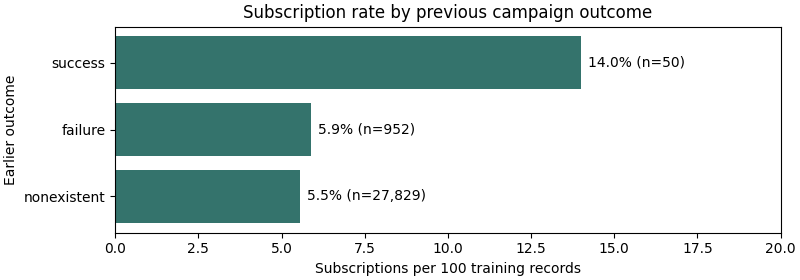

In [6]:
history = train.groupby("poutcome")[target].agg(
    records="size", subscribers=lambda answers: answers.eq("yes").sum()
)
history["response_pct"] = 100 * history["subscribers"] / history["records"]
print(history.round(2).to_string())

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 2.8), constrained_layout=True)
rates = history.sort_values("response_pct")
bars = ax.barh(rates.index, rates["response_pct"], color="#34736c")
ax.bar_label(bars, labels=[f"{rate:.1f}% (n={size:,})"
                          for rate, size in zip(rates["response_pct"], rates["records"])],
             padding=5)
ax.set(xlim=(0, 20), xlabel="Subscriptions per 100 training records",
       ylabel="Earlier outcome", title="Subscription rate by previous campaign outcome")
plt.show()

Seven of the 50 records with a previous success ended in a new subscription (14.0%). Among records with no previous outcome, 1,543 of 27,829 subscribed (5.54%). This is an association among people the bank contacted. The small success group and historical contact selection limit what we can infer about future customers or the effect of calling them.

**Decision for Part 3.** Keep the original three pre-call inputs, preserve the difference between unknown job and absent campaign history, and learn preprocessing rules on the training split. The validation and test response distributions have not been used for these decisions.

## Part 3 · Prepare the pre-call inputs

**Question.** How can the model read a contact count and two text labels in a consistent way, even when the next contact has an unfamiliar job? We build one reusable transformer and check its behaviour before training a classifier. Every transformation is fitted on the 28,831 training records.

### 3.1 · Separate clues from the answer

Select the three approved fields by name. This keeps the subscription label and the length of the current call out of the input matrix. Validation rows use the same three columns in the same order. The reserved test records remain available for final evaluation.

In [7]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_fields = ["previous"]
category_fields = ["job", "poutcome"]
assert set(numeric_fields + category_fields) == set(pre_call_features)
X_train = train.loc[:, pre_call_features]
X_validation = validation.loc[:, pre_call_features]
y_train = train[target]
print("Pre-call inputs:", ", ".join(X_train.columns))

Pre-call inputs: job, previous, poutcome


### 3.2 · Give each kind of input a suitable representation

| Input | Preparation | Reason |
|---|---|---|
| Earlier contact count | Fill missing numbers with the training median, then standardize | Keep a recorded zero as a valid count. Scaling puts the numeric input on a consistent scale for regularized logistic regression. |
| Job and prior campaign outcome | Fill a missing label with `unknown`, then create one indicator per observed category | Each known label has a distinct meaning. In particular, `nonexistent` represents no prior campaign outcome. |
| Unseen category | Use zeros in that field’s indicator columns | A new label can pass through the trained pipeline without changing the number of inputs. This fallback cannot learn an effect specific to a label absent during fitting. |

A recorded `unknown` job already appears during training, so it gets its own column. For a field where `unknown` never appeared during fitting, a missing label follows the unseen-category fallback.

In [8]:
number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("number", number_steps, numeric_fields),
    ("category", category_steps, category_fields),
]).set_output(transform="pandas")

prepared_train = preprocessor.fit_transform(X_train)
prepared_validation = preprocessor.transform(X_validation)
assert prepared_train.columns.equals(prepared_validation.columns)
assert prepared_train.index.equals(X_train.index)
assert prepared_validation.index.equals(X_validation.index)
assert np.isfinite(prepared_train).all().all() and np.isfinite(prepared_validation).all().all()
print("Training rows and columns:", prepared_train.shape)
print("Validation rows and columns:", prepared_validation.shape)
print("Previous-outcome indicators:", [c for c in prepared_train if "poutcome_" in c])

Training rows and columns: (28831, 16)
Validation rows and columns: (6178, 16)
Previous-outcome indicators: ['category__poutcome_failure', 'category__poutcome_nonexistent', 'category__poutcome_success']


### 3.3 · Check missing and unfamiliar values

The following two rows are invented solely to test the transformer. The first has a missing job and contact count. The second has a job label absent from training. Inspecting the indicator values lets us check the actual behaviour that a future dashboard will rely on.

In [9]:
examples = pd.DataFrame([
    {"job": np.nan, "previous": np.nan, "poutcome": "nonexistent"},
    {"job": "new_job_example", "previous": 0, "poutcome": "nonexistent"},
], index=["missing fields", "unseen job"])
encoded = preprocessor.transform(examples)
job_columns = encoded.filter(like="category__job_")
assert np.isfinite(encoded).all().all()
assert encoded.loc["missing fields", "category__job_unknown"] == 1
assert job_columns.loc["unseen job"].sum() == 0
assert encoded["category__poutcome_nonexistent"].eq(1).all()
print(pd.DataFrame({
    "unknown job indicator": encoded["category__job_unknown"],
    "active job indicators": job_columns.sum(axis=1),
    "no prior outcome indicator": encoded["category__poutcome_nonexistent"],
}).to_string())

                unknown job indicator  active job indicators  no prior outcome indicator
missing fields                    1.0                    1.0                         1.0
unseen job                        0.0                    0.0                         1.0


**Result.** Three raw fields became 16 numeric columns: one scaled count, 12 job indicators and three previous-outcome indicators. All training and validation rows were retained. The example checks show that an unfamiliar job leaves the known previous-outcome signal intact. Part 4 will use these preparation rules to compare a baseline with logistic regression on validation records.

## Part 4 · Can three pre-call inputs rank likely subscribers?

A campaign team with limited call capacity needs a useful ranking before it can choose how many people to flag. We compare two methods on the same later validation records. **Average precision (AP)** is our main comparison: it summarizes precision as we move down the ranked list and reach more actual subscribers. Higher values indicate a better ranking for this task.

### 4.1 · Fit both models using earlier records

The baseline gives every contact the training subscription rate. It establishes what happens when the model cannot distinguish one contact from another. Logistic regression learns weights for the three pre-call inputs and produces a score for a “yes” response. We place a fresh copy of the Part 3 transformer inside the pipeline so the fitted model can accept raw inputs later.

In [10]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

baseline = DummyClassifier(strategy="prior")
logistic_model = Pipeline([
    ("prepare", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000)),
])
validation_yes = validation[target].eq("yes")
validation_scores = {}
for name, model in [("Prior baseline", baseline), ("Logistic regression", logistic_model)]:
    model.fit(X_train, y_train)
    yes_column = model.classes_.tolist().index("yes")
    validation_scores[name] = model.predict_proba(X_validation)[:, yes_column]

print(f"Validation subscriptions: {validation_yes.sum():,} of {len(validation_yes):,}")
print(f"Training subscription rate: {y_train.eq('yes').mean():.2%}")
print(f"Validation subscription rate: {validation_yes.mean():.2%}")

Validation subscriptions: 658 of 6,178
Training subscription rate: 5.57%
Validation subscription rate: 10.65%


### 4.2 · Separate ranking quality from the decision to call

ROC AUC measures how often a subscriber ranks above a non-subscriber, giving half credit for ties. For a constant score, ROC AUC is 0.5 and AP equals the validation subscription rate. We also count how many contacts would be flagged at 0.50 as a diagnostic. Part 5 will use validation data to choose an operating cutoff.

In [11]:
rows = []
for name, scores in validation_scores.items():
    flagged = scores >= 0.50
    found = int((validation_yes & flagged).sum())
    rows.append({
        "Model": name,
        "Average precision": average_precision_score(validation_yes, scores),
        "ROC AUC": roc_auc_score(validation_yes, scores),
        "Flagged at 0.50": int(flagged.sum()),
        "Subscribers found": found,
        "Subscribers missed": int(validation_yes.sum()) - found,
    })

comparison = pd.DataFrame(rows).set_index("Model")
assert np.isclose(comparison.loc["Prior baseline", "Average precision"], validation_yes.mean())
print(comparison.round(4).to_string())

                     Average precision  ROC AUC  Flagged at 0.50  Subscribers found  Subscribers missed
Model                                                                                                  
Prior baseline                  0.1065   0.5000                0                  0                 658
Logistic regression             0.1798   0.5887                0                  0                 658


### 4.3 · Interpretation and next decision

On the 6,178 validation contacts, logistic regression achieved **0.180 average precision** and **0.589 ROC AUC**. The constant baseline achieved **0.107** and **0.500**, respectively. The higher AP supports carrying logistic regression forward for cutoff selection. At a 0.50 cutoff it flagged **0** contacts and missed **658** subscribers. The ranking and the decision rule answer different business questions.

The subscription rate changed from 5.57% during training to 10.65% during validation. This observed difference makes it important to evaluate the eventual policy on later records. Ranking metrics alone cannot establish that a score of 0.20 corresponds to a 20% response rate. Final test performance remains to be measured.

## Part 5 · Choose a cutoff and evaluate the final policy

**Decision.** Flag a contact when the logistic-regression score meets or exceeds a cutoff. A lower cutoff can find more subscribers, but it can also flag more people who decline. We have no verified call budget, cost per call or revenue per subscription. For this portfolio demonstration, choose the cutoff with the highest validation F1 score, the harmonic mean of precision and recall. If multiple cutoffs tie, choose the highest to limit call volume. A bank with known costs or a strict call limit could choose a different rule.

### 5.1 · Select using validation records only

Evaluate every distinct validation score as a candidate. Contacts with identical scores receive the same decision. Compare the selected policy with flagging everyone and the original 0.50 cutoff so that the trade-off is visible in counts as well as rates.

In [12]:
from sklearn.metrics import confusion_matrix, precision_recall_curve

def policy_results(labels, scores, cutoff):
    flags = scores >= cutoff
    tn, fp, fn, tp = confusion_matrix(labels, flags, labels=[False, True]).ravel()
    return {
        "flagged": int(tp + fp), "found": int(tp), "false positives": int(fp),
        "missed": int(fn), "true negatives": int(tn),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
    }

val_scores = validation_scores["Logistic regression"]
precision, recall, cutoffs = precision_recall_curve(validation_yes, val_scores)
# The last point on the curve has no corresponding threshold.
precision, recall = precision[:-1], recall[:-1]
total = precision + recall
f1 = np.divide(2 * precision * recall, total, out=np.zeros_like(total), where=total > 0)
selected_cutoff = cutoffs[np.isclose(f1, f1.max(), rtol=0, atol=1e-12)].max()
policies = {"Flag everyone": 0.0, "Selected on validation": selected_cutoff, "Default": 0.5}
validation_policies = pd.DataFrame({
    name: policy_results(validation_yes, val_scores, cutoff)
    for name, cutoff in policies.items()
}).T
print(f"Selected cutoff: {selected_cutoff:.8f} (full precision retained in code)")
print(validation_policies.round(3).to_string())

Selected cutoff: 0.09240519 (full precision retained in code)
                        flagged  found  false positives  missed  true negatives  precision  recall     F1
Flag everyone            6178.0  658.0           5520.0     0.0             0.0      0.107   1.000  0.193
Selected on validation    431.0  131.0            300.0   527.0          5220.0      0.304   0.199  0.241
Default                     0.0    0.0              0.0   658.0          5520.0      0.000   0.000  0.000


### 5.2 · Apply the locked policy to the latest records

Keep both the fitted Part 4 pipeline and the full-precision cutoff unchanged. Refitting the model could change its scores and invalidate the selected cutoff. Compare with the simple policy of flagging everyone, and report ranking metrics as a separate check. “Found” means a flagged record had a historical yes outcome; these counts do not estimate subscriptions caused by making calls.

In [13]:
X_test = test.loc[:, pre_call_features]
test_yes = test[target].eq("yes")
yes_column = logistic_model.classes_.tolist().index("yes")
test_scores = logistic_model.predict_proba(X_test)[:, yes_column]
test_result = policy_results(test_yes, test_scores, selected_cutoff)
test_policies = pd.DataFrame({
    "Flag everyone": policy_results(test_yes, test_scores, 0.0),
    "Locked policy": test_result,
}).T
assert test_result["found"] + test_result["missed"] == test_yes.sum()
assert test_result["flagged"] + test_result["true negatives"] + test_result["missed"] == len(test)
print(test_policies.round(3).to_string())
print(f"Test subscription rate: {test_yes.mean():.2%}")
print(f"Test average precision: {average_precision_score(test_yes, test_scores):.3f}")
print(f"Test ROC AUC: {roc_auc_score(test_yes, test_scores):.3f}")

               flagged   found  false positives  missed  true negatives  precision  recall     F1
Flag everyone   6179.0  2376.0           3803.0     0.0             0.0      0.385   1.000  0.555
Locked policy   2095.0  1150.0            945.0  1226.0          2858.0      0.549   0.484  0.514
Test subscription rate: 38.45%
Test average precision: 0.555
Test ROC AUC: 0.642


### 5.3 · What the test result means

The validation-selected cutoff was **0.09241** (rounded for display). On validation it flagged 431 of 6,178 contacts. On the 6,179 later test records it flagged **2,095**: **1,150** subscribed and **945** declined. It missed **1,226** of the 2,376 recorded subscribers. Precision was **54.9%**, recall **48.4%**, and F1 **0.514**.

Flagging everyone achieved F1 **0.555** on the same test period and required flagging every record. The subscription rate changed from 10.7% in validation to 38.5% in testing, so neither call volume nor recall should be assumed stable. Keep the locked result as the benchmark for the dashboard. Any future policy tuning informed by these test outcomes needs a new evaluation period.

## Part 6 · Publish the predictor and cutoff dashboard

The fitted pipeline scores the three inputs supported by the form. Export a lookup table covering training job labels and observed contact counts. Restrict zero previous contacts to “nonexistent” and positive counts to a recorded previous success or failure. This is a demonstration of the evaluated model on a limited input range.

In [14]:
import json
from itertools import product

jobs = sorted(X_train["job"].unique().tolist())
counts = sorted(int(x) for x in X_train["previous"].unique())
examples = [
    (job, previous, outcome)
    for job, previous in product(jobs, counts)
    for outcome in (["nonexistent"] if previous == 0 else ["failure", "success"])
]
form_inputs = pd.DataFrame(examples, columns=pre_call_features)
example_scores = logistic_model.predict_proba(form_inputs)[:, yes_column]
lookup = {json.dumps(row, separators=(",", ":")): float(score)
          for row, score in zip(examples, example_scores)}
print(f"Exported {len(lookup)} input combinations from the fitted pipeline.")

Exported 84 input combinations from the fitted pipeline.


### Reproduce the locked operating point

Group the historical test records by score. For each score, keep the number of records and recorded subscriptions. These counts let the dashboard evaluate different cutoffs without sharing individual records. Changing the cutoff changes the call decision; it leaves the example contact’s model score unchanged.

In [15]:
grouped = (pd.DataFrame({"score": test_scores, "yes": test_yes.to_numpy()})
           .groupby("score")["yes"].agg(["size", "sum"]))
groups = [[float(score), int(row["size"]), int(row["sum"])]
          for score, row in grouped.iterrows()]
selected = [row for row in groups if row[0] >= selected_cutoff]
assert sum(row[1] for row in selected) == test_result["flagged"]
assert sum(row[2] for row in selected) == test_result["found"]
payload = {"jobs": jobs, "counts": counts, "lookup": lookup,
           "groups": groups, "cutoff": float(selected_cutoff),
           "n": len(test), "positives": int(test_yes.sum())}
template = Path("dashboard/template.html").read_text(encoding="utf-8")
assert template.count("__MODEL_DATA__") == 1
Path("dashboard/index.html").write_text(
    template.replace("__MODEL_DATA__", json.dumps(payload, separators=(",", ":"))),
    encoding="utf-8",
)
print(f"Dashboard default: {test_result['flagged']:,} flagged; {test_result['found']:,} subscribers found.")

Dashboard default: 2,095 flagged; 1,150 subscribers found.


**Try it:** Change the example contact, move the cutoff, then restore the published policy. At zero, all 6,179 contacts are flagged. At the selected cutoff, 2,095 qualify and 1,150 subscribed. Slider experiments on this test period are retrospective. They cannot establish the effect of making a call.